In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [5]:
import pathlib
root = pathlib.Path('C:\\Users\\vitko\\Desktop\\CVR\\Data\\labeled')
training_output_root = pathlib.Path('C:\\Users\\vitko\\Desktop\\CVR')

In [6]:
import delisa_loader
x,y = delisa_loader.load_pairs(root)

assert len(x) == len(y)
assert len(x) > 0

print("Found training pairs", len(x))

test_x,test_y = delisa_loader.load_pairs(root/'../../test')
assert len(test_x) == len(test_y)
assert len(test_x) > 0
print("Found testing pairs", len(test_x))

Found training pairs 33
Found testing pairs 6


In [7]:
import numpy as np
import denoiseg.configuration as cfg
default_params = cfg.get_default_config()

custom = {
    "patch_size":256,
    "epochs":200,
    "patience":20,
    "dataset_repeat":100,
    "denoise_enabled":False,
    "validation_set_percentage":.2,
    "model":{
        "filters":8,
        "depth":5,
    },
    "note":"added filters",
    "augumentation":{
        "brightness_contrast":True,
        "noise_val":0.001,
        "flip_vertical": True,
        "flip_horizontal": True,
        "rotate_deg": 190,
        "elastic":True,
        "blur_sharp_power": 1,
    }
}

train_params = cfg.merge(default_params,custom)

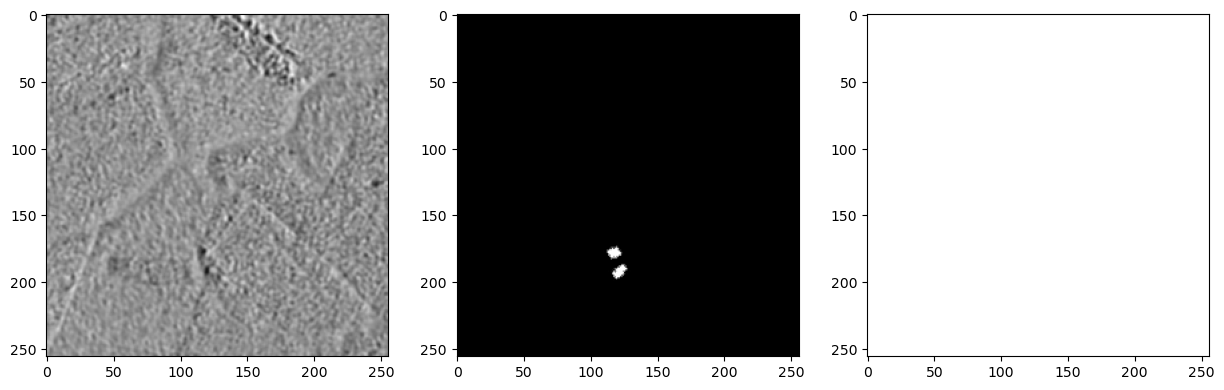

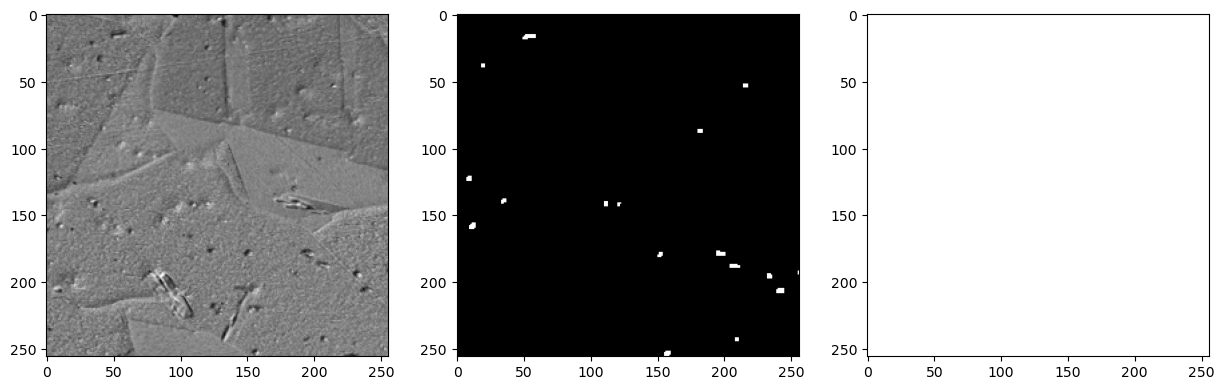

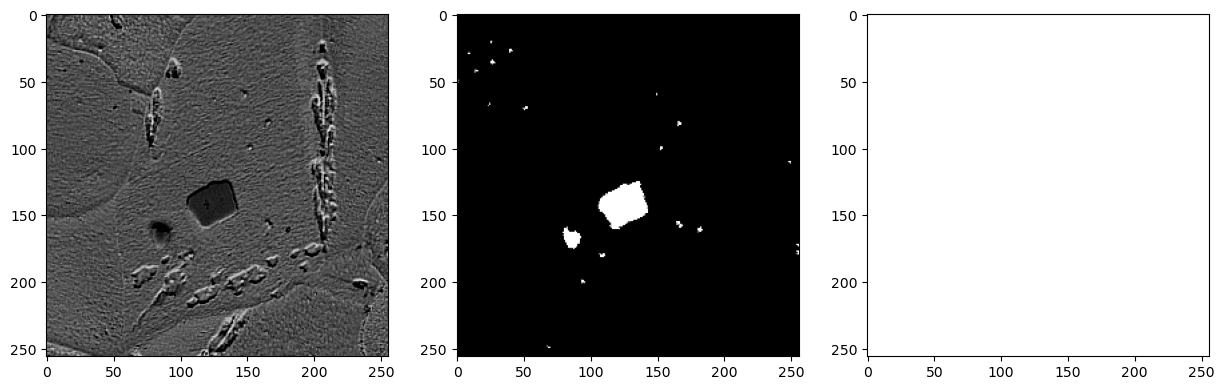

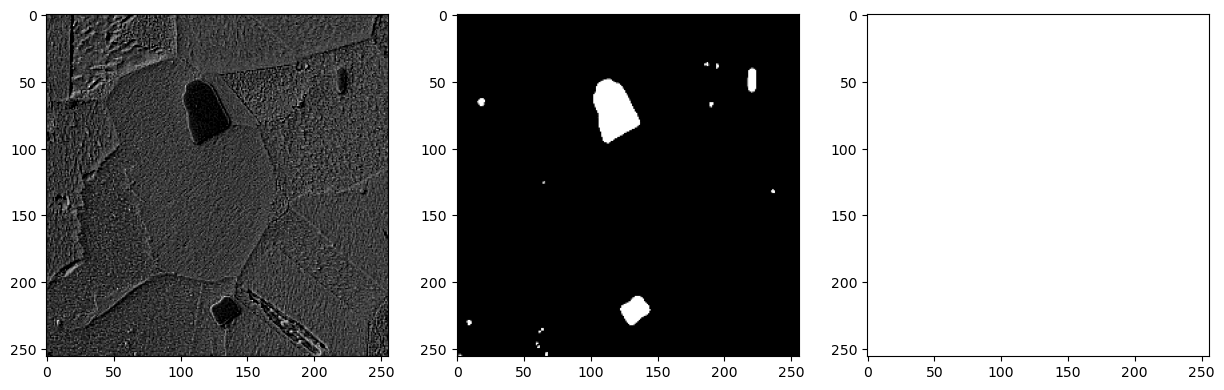

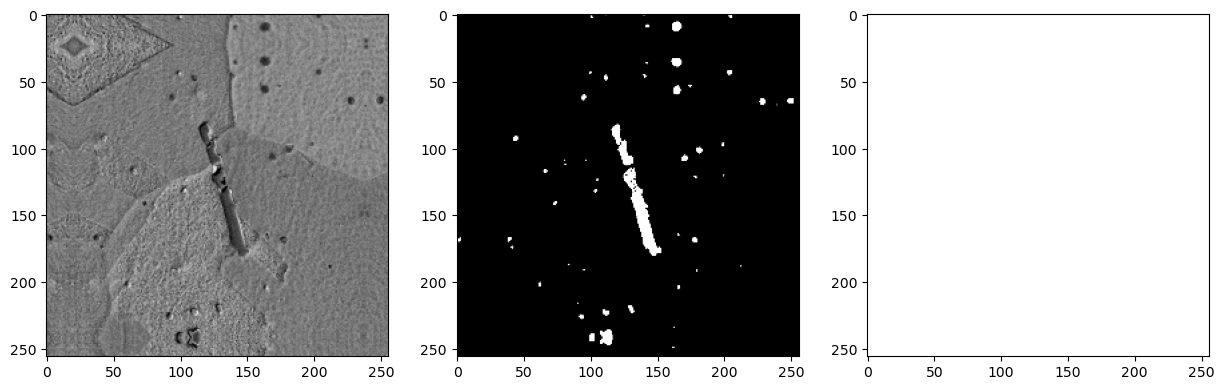

In [9]:
import denoiseg.visualization as vis

vis.sample_ds(
    x,
    y,
    train_params,
    #weightmaps= weightmaps,  # Use this when you want to add weightmaps. Its usefull to force CNN to separate objects
    n=5
)

# Training

In [10]:
import segmentation_models_pytorch as smp

encoder = "resnet18"
decoder_attention_type = None #"scse"
activation = 'sigmoid'


#POZOR: tady jsou 4 output vrstvy
# 1. foreground
# 2. background
# 3. borders
# denoise (to neřešíme)


model = smp.Unet(
    encoder_name=encoder,           # choose encoder, e.g. mobilenet_v2 or efficientnet-b7
    encoder_weights="imagenet",     # use `imagenet` pre-trained weights for encoder initialization
    in_channels=3,                  # model input channels (1 for gray-scale images, 3 for RGB, etc.)
    classes=4,                      # model output channels (number of classes in your dataset)
    decoder_attention_type=decoder_attention_type,
    activation=activation
)

In [11]:
import denoiseg.segmentation as seg
from tqdm.contrib.logging import logging_redirect_tqdm

with logging_redirect_tqdm():
    checkpoint, out_losses =seg.run_training(
        x,
        y,
        train_params, 
        training_output_root,
        device = device,
        #weightmaps = weightmaps,
        model = model
    )


INFO:segmentation:Filtering out denoise images
INFO:segmentation:Batches:len(train_dataloader)=1
INFO:segmentation:Batches:len(val_dataloader)=1
INFO:denoiseg:Setting up loss. denoise_loss_weight=0.01, denoise_enabled=False
INFO:denoiseg:Training started


Training epochs:   0%|          | 0/200 [00:00<?, ?it/s]

DEBUG:denoiseg:learning rate: 0.001
INFO:denoiseg:checkpoint best model before_val_loss=inf -> 0.19823
INFO:denoiseg:epoch=0 loss_val=0.19823


KeyboardInterrupt: 

In [1]:
import denoiseg.visualization as vis
import matplotlib.pyplot as plt

vis.plot_loss(out_losses)
plt.show()

NameError: name 'out_losses' is not defined

# Evaluate

In [1]:
import denoiseg.training as tr
from tqdm.auto import tqdm
import denoiseg.evaluation as ev

checkpoint = "C:\\Users\\vitko\\Desktop\\CVR\\20240717002951\\model-checkpoint-best.pth"
model = torch.load(checkpoint)
predictions, metrics = ev.evaluate_images(
    model, 
    test_x,
    test_y,
    device = device
)

print(f'Mean IoU {np.mean(metrics):.5f}')

NameError: name 'torch' is not defined

In [ ]:
print(f"x,y,prediction")
for i,(img,gt,pred,met) in enumerate(zip(test_x,test_y,predictions,metrics)):
    
    segms = []
    for im in pred[1:]:
        im = im.copy()
        im = (im - np.min(im))/(np.max(im)-np.min(im))
        im[im<.5] = 0
        im[im>=.5] = 1
        segms.append(im)

    show_imgs = [img,gt,segms[0]]
    vis.plot_row(show_imgs,vmin_vmax = (0,1),figsize=(50,20))
    plt.suptitle(f'Metric: {met}')
    plt.tight_layout()
    plt.show()

# Evaluation

The following code represent instance evalutaion with different thresholds. The results are visualized ina  form or precision recall curve.

Each point represents mean evaluation for a given model across the whole test set. The evaluation encapsulates two compontens:
- precision = TP/(TP+FN)
- recall = TP/(TP + TN)
- The final value $f_1$ is it's harmonic mean. 

Each datapoint shows $f_1$ and $t$ which reffers the the threshold this value has been obtained with

Matching prec: 0it [00:00, ?it/s]

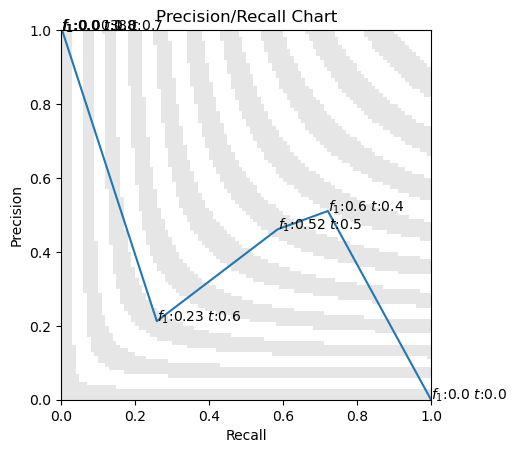

In [16]:
import denoiseg.instance_analysis as ia

# HACK bacward compatibility problem
preds = [p[1:] for p in predictions]
evaluations = ia.evaluate_match(test_x,test_y,preds)
mean_evaluations = ia.mean_evaluations(evaluations)
vis.plot_precision_recall_curve(mean_evaluations)

# Image Synthesis

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import scipy
from PIL import ImageFilter, Image


def add_potato_shapes(image, min_potato_num, max_potato_num, bg):
    num = np.random.randint(min_potato_num, max_potato_num)

    for _ in range(num):
        center = (np.random.randint(20, image.shape[0] - 20), np.random.randint(20, image.shape[1] - 20))
        size = (np.random.randint(2, 25), np.random.randint(2, 10))
        angle = np.random.randint(0, 180)
        color = (30, 30, 30)

        # perturb_contour_spiky(image, center, axes, angle, color)
        perturb_contour_smooth(image, center, size, angle, color)
        image = cv2.ellipse(image, center, size, angle, 0, 360, color, -1)

    # copy just the effect of emboss, otherwise the image will be mostly grey
    emb_image, emb_mask = add_emboss(image)
    image[emb_mask] = emb_image[emb_mask]

    # warning: blob part can't have bg color
    mask = (image != bg) * 255

    return image, mask


def perturb_contour_spiky(image, center, size, angle, color):
    ellipse_contour = cv2.ellipse(np.zeros((400, 400), dtype=np.uint8), center, size, angle, 0, 360, color, 5)
    contours, _ = cv2.findContours(ellipse_contour, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cont in contours:
        for point in cont:
            point[0][0] += np.random.randint(-2, 2)
            point[0][1] += np.random.randint(-2, 2)

    return cv2.drawContours(image, contours, -1, color, -1)


def perturb_contour_smooth(image, center, size, angle, color):
    ellipse_contour = cv2.ellipse(np.zeros((400, 400), dtype=np.uint8), center, size, angle, 0, 360, color, 4)
    contours, _ = cv2.findContours(ellipse_contour, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    for cont in contours:
        noise = np.random.normal(0, 5, (len(cont), 2))
        smooth_noise = cv2.GaussianBlur(np.array(noise), (0, 0), sigmaX=10, sigmaY=10, borderType=cv2.BORDER_REFLECT)
        for i, point in enumerate(cont):
            point[0][0] += smooth_noise[i][0]
            point[0][1] += smooth_noise[i][1]

    cv2.drawContours(image, contours, -1, color, -1)


def add_emboss(image):
    pil_image = Image.fromarray(image.astype('uint8'), 'L')
    kernel = (-1, 0, 0, 0, 0,
              0, 0, 0, 0, 0,
              0, 0, 0, 0, 0,
              0, 0, 0, 0, 0,
              0, 0, 0, 0, 1)
    kernel = (
        1, 0, 0,
        0, 0, 0,
        0, 0, -1
    )

    ImageFilter.EMBOSS.filterargs = ((3, 3), 1, 128, kernel)
    embossed_image = np.array(pil_image.filter(ImageFilter.EMBOSS))

    mask = embossed_image != 128
    return embossed_image, mask


def generate_image(image_size, min_potato_num, max_potato_num):
    background_shade = np.random.randint(75, 150)
    image = np.full(image_size, background_shade, dtype=np.uint8)
    image, mask = add_potato_shapes(image, min_potato_num, max_potato_num, background_shade)

    return image, mask


for i in range(5):
    img, mask = generate_image((400, 400), 2, 10)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(img, cmap='gray')
    axes[0].axis('off')
    axes[1].imshow(mask, cmap='gray')
    axes[1].axis('off')

    plt.show()

